# Ejercicio: Taller de Feature Engineering

**Bootcamp:** Python - PY4
**Modulo:** Machine Learning Avanzado y Feature Engineering  
**Dataset asignado:** Seoul Bike Sharing Demand

## Consigna

Este es el ejercicio final del taller. Vas a aplicar, por tu cuenta, el mismo proceso que practicamos en las sesiones anteriores, pero con un dataset distinto (bicicletas compartidas en Seul, en vez de Washington D.C.).

Tu problema es de **regresion**: la variable objetivo es `rented_bike_count`, la cantidad de bicicletas rentadas en una hora especifica.

El ejercicio tiene 2 partes, mas una comparativa final:

- **Parte 1**: Modelo Baseline + Ingenieria de Caracteristicas. Entrenar un modelo simple, registrar sus metricas, y despues aplicar al menos 3 de estas 4 tecnicas: log-transform/Box-Cox, Winsorization o variable indicadora, Target Encoding, transformacion seno/coseno.
- **Parte 2**: Optimizacion con Optuna. Definir el espacio de busqueda, correr el estudio, y generar el grafico `plot_param_importances`.
- **Comparativa Final**: tabla Modelo Inicial vs. Modelo Optimizado, y una conclusion de maximo 200 palabras.

### Una aclaracion importante sobre los modelos

En este ejercicio vamos a usar **dos modelos distintos a proposito**:

- **Parte 1**: vamos a usar **Regresion Lineal** (`LinearRegression`). Este modelo es sensible a la escala y a la forma de las variables, asi que el efecto del feature engineering se va a notar claramente.
- **Parte 2**: vamos a cambiar a **XGBoost** (`XGBRegressor`). A diferencia de Random Forest, XGBoost construye los arboles de forma secuencial (cada uno corrige los errores del anterior), lo que lo hace mucho mas sensible a sus hiperparametros. Esto le da a Optuna un espacio de busqueda mas rico, y es mas probable que veas una mejora real y visible al optimizarlo.

Esto significa que en la Comparativa Final vas a estar comparando el Modelo Inicial (Regresion Lineal, sin feature engineering) contra el Modelo Optimizado (XGBoost, con las features de la Parte 1, mas el tuning de Optuna)

## Preparacion

Esta parte no es evaluada, asi que la dejamos lista para que puedas enfocarte en lo que si importa. Cargamos el dataset, y hacemos una limpieza minima de "plomeria" (nada de feature engineering todavia): renombramos columnas, convertimos la fecha a formato de fecha real, y codificamos de forma simple un par de columnas de texto para que un modelo pueda usarlas.


In [2]:
!pip install optuna xgboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 11.6 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from xgboost import XGBRegressor

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
sns.set_style("whitegrid")


In [4]:
URL = "https://raw.githubusercontent.com/minjiontheroad/seoul-bike-demand/main/SeoulBikeData.csv"

# Este dataset viene con codificacion latin1, no utf-8 (por los caracteres especiales en los nombres de columna)
df = pd.read_csv(URL, encoding="latin1")

# Renombramos columnas para que sean mas comodas de usar en codigo
df = df.rename(columns={
    "Date": "date",
    "Rented Bike Count": "rented_bike_count",
    "Hour": "hour",
    "Temperature(°C)": "temperature",
    "Humidity(%)": "humidity",
    "Wind speed (m/s)": "wind_speed",
    "Visibility (10m)": "visibility",
    "Dew point temperature(°C)": "dew_point_temperature",
    "Solar Radiation (MJ/m2)": "solar_radiation",
    "Rainfall(mm)": "rainfall",
    "Snowfall (cm)": "snowfall",
    "Seasons": "season",
    "Holiday": "holiday",
    "Functioning Day": "functioning_day",
})

# Convertimos la fecha de texto a un dato de tipo fecha, y extraemos el mes
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
df["month"] = df["date"].dt.month

# Codificacion simple (no es Target Encoding, es solo para poder usar estas columnas en un modelo)
df["holiday_enc"] = df["holiday"].map({"Holiday": 1, "No Holiday": 0})
df["season_enc"] = df["season"].map({"Winter": 0, "Spring": 1, "Summer": 2, "Autumn": 3})

df.head()


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,season,holiday,functioning_day,month,holiday_enc,season_enc
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,0,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,0,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,12,0,0
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,0,0
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,0,0


### Antes de seguir: revisa la columna `functioning_day`

Esta columna indica si el sistema de bicicletas estaba operativo en esa hora (`Yes`) o cerrado (`No`). Investiga que pasa con `rented_bike_count` en las filas donde `functioning_day` es `No`, y decide si conviene dejarlas, o filtrarlas antes de entrenar cualquier modelo. Justifica tu decision en una celda de markdown.


In [5]:
print(df.groupby("functioning_day")["rented_bike_count"].describe())


                  count        mean         std  min    25%    50%     75%  \
functioning_day                                                              
No                295.0    0.000000    0.000000  0.0    0.0    0.0     0.0   
Yes              8465.0  729.156999  642.351166  2.0  214.0  542.0  1084.0   

                    max  
functioning_day          
No                  0.0  
Yes              3556.0  


Cuando `functioning_day` es `"No"`, `rented_bike_count` es siempre 0: el sistema estaba cerrado esas horas, asi que no hay demanda real que predecir. Dejar esas filas solo le enseñaria al modelo un patron trivial (sistema cerrado = 0 bicis) que no aporta nada util para el problema real de negocio, que es predecir demanda cuando el sistema esta operativo. Por eso decido filtrarlas antes de entrenar cualquier modelo.


In [6]:
df = df[df["functioning_day"] == "Yes"].reset_index(drop=True)
print(df.shape)


(8465, 17)


## Parte 1: Modelo Baseline e Ingenieria de Caracteristicas

### Paso 1.1: Exploracion rapida

Antes de armar el modelo, revisa el dataset: cuantas filas y columnas tiene, si hay valores nulos, y como se ve la distribucion de la variable objetivo (`rented_bike_count`). No hace falta limpieza profunda todavia, solo un vistazo general.


In [7]:
print("Shape:", df.shape)
print()
df.info()
print()
print("Nulos por columna:")
print(df.isnull().sum())


Shape: (8465, 17)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   8465 non-null   datetime64[ns]
 1   rented_bike_count      8465 non-null   int64         
 2   hour                   8465 non-null   int64         
 3   temperature            8465 non-null   float64       
 4   humidity               8465 non-null   int64         
 5   wind_speed             8465 non-null   float64       
 6   visibility             8465 non-null   int64         
 7   dew_point_temperature  8465 non-null   float64       
 8   solar_radiation        8465 non-null   float64       
 9   rainfall               8465 non-null   float64       
 10  snowfall               8465 non-null   float64       
 11  season                 8465 non-null   object        
 12  holiday                8465 non-null   obje

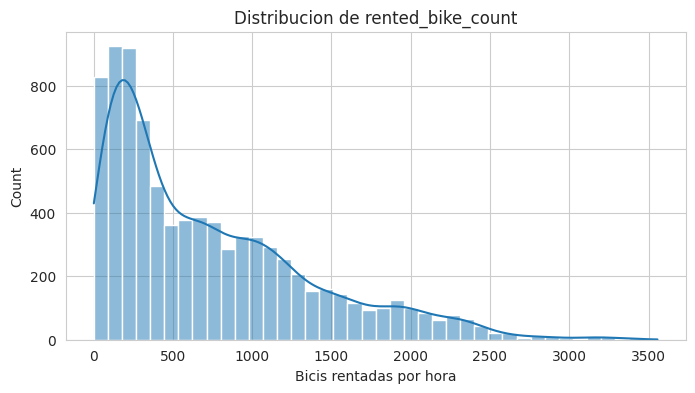

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(df["rented_bike_count"], bins=40, kde=True)
plt.title("Distribucion de rented_bike_count")
plt.xlabel("Bicis rentadas por hora")
plt.show()


### Paso 1.2: Separar features y target, y hacer el train/test split

Elige que columnas vas a usar como features para el baseline (no hace falta usar todas las que estan disponibles: piensa cuales tienen sentido y cuales no; por ejemplo, la columna `date` original ya no la necesitas porque extrajimos `month` en la preparacion).

Usa `random_state=RANDOM_STATE` en el split, para que tus resultados sean reproducibles.


In [9]:
features_base = [
    "hour", "temperature", "humidity", "wind_speed", "visibility",
    "dew_point_temperature", "solar_radiation", "rainfall", "snowfall",
    "month", "holiday_enc", "season_enc",
]

X = df[features_base].copy()
y = df["rented_bike_count"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)


(6772, 12) (1693, 12)


### Paso 1.3: Entrenar el modelo baseline

Recuerda: en esta parte usamos **Regresion Lineal**, sin ninguna tecnica de feature engineering todavia.


In [10]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)


LinearRegression()

### Paso 1.4: Evaluar el baseline

Calcula el RMSE y el R2 sobre el conjunto de prueba, y guardalos en variables (las vas a necesitar en la Comparativa Final).


In [11]:
y_pred_inicial = baseline_model.predict(X_test)

rmse_inicial = mean_squared_error(y_test, y_pred_inicial) ** 0.5
r2_inicial = r2_score(y_test, y_pred_inicial)

print(f"RMSE inicial: {rmse_inicial:.2f}")
print(f"R2 inicial: {r2_inicial:.4f}")


RMSE inicial: 420.09
R2 inicial: 0.5505


**Registro de metricas baseline**:

- RMSE inicial: 420.09
- R2 inicial: 0.5505

### Ingenieria de caracteristicas

Aplica al menos 3 de las siguientes 4 tecnicas. Para cada una, primero investiga si tiene sentido aplicarla a este dataset (con un grafico o una estadistica rapida), y despues impleméntala. Segui evaluando con la misma Regresion Lineal en cada paso, para que la comparacion contra el baseline sea directa.

#### Tecnica


Skew original: 1.139498090026039
Skew con log1p: -0.7703380833481573


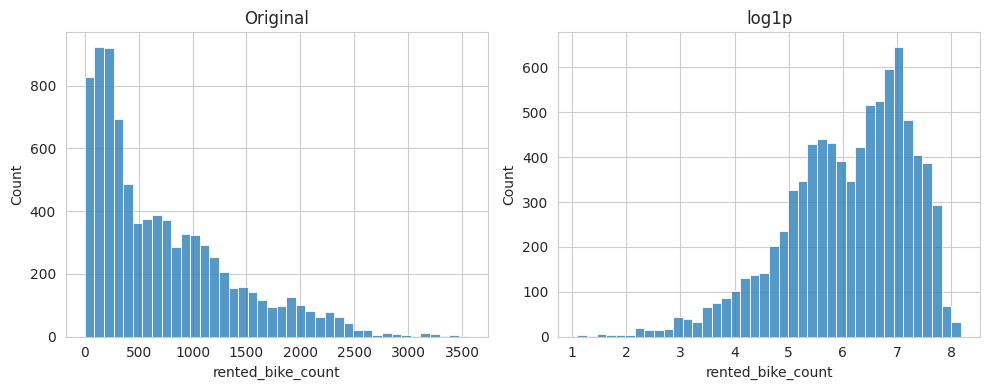

In [12]:
from scipy.stats import skew

print("Skew original:", skew(df["rented_bike_count"]))
print("Skew con log1p:", skew(np.log1p(df["rented_bike_count"])))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["rented_bike_count"], bins=40, ax=axes[0])
axes[0].set_title("Original")
sns.histplot(np.log1p(df["rented_bike_count"]), bins=40, ax=axes[1])
axes[1].set_title("log1p")
plt.tight_layout()
plt.show()


In [13]:
# El skew baja bastante con log1p, asi que aplico la transformacion al target
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)


#### Tecnica 2: Outliers (Winsorization o variable indicadora)

Elige una o dos columnas numericas que tengan valores extremos (por ejemplo, `wind_speed`, `rainfall` o `solar_radiation` son buenas candidatas: revisalas con un boxplot o con `describe()`). Aplica Winsorization (recorte a un percentil, calculado solo con el train) y crea una variable indicadora de "es outlier".

Recuerda: los percentiles de corte se calculan **solo con el conjunto de entrenamiento**, y despues se aplican igual al conjunto de prueba.


count    6772.000000
mean        0.149985
std         1.087939
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        35.000000
Name: rainfall, dtype: float64


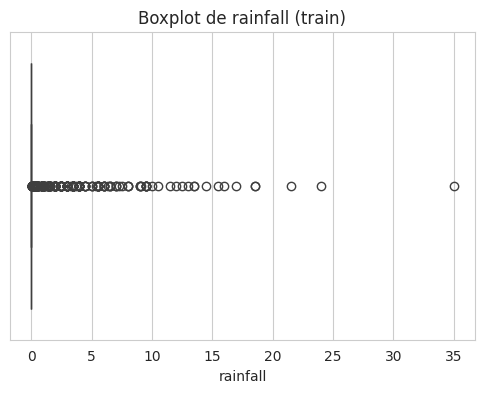

In [14]:
print(X_train["rainfall"].describe())

plt.figure(figsize=(6, 4))
sns.boxplot(x=X_train["rainfall"])
plt.title("Boxplot de rainfall (train)")
plt.show()


In [15]:
p05 = X_train["rainfall"].quantile(0.05)
p95 = X_train["rainfall"].quantile(0.95)

print(f"Limites (calculados solo con train): p05={p05}, p95={p95}")

X_train["rainfall_is_outlier"] = ((X_train["rainfall"] < p05) | (X_train["rainfall"] > p95)).astype(int)
X_test["rainfall_is_outlier"] = ((X_test["rainfall"] < p05) | (X_test["rainfall"] > p95)).astype(int)

X_train["rainfall"] = X_train["rainfall"].clip(lower=p05, upper=p95)
X_test["rainfall"] = X_test["rainfall"].clip(lower=p05, upper=p95)


Limites (calculados solo con train): p05=0.0, p95=0.5


#### Tecnica 3: Encoding (Target Encoding)

Piensa cual columna categorica de tu dataset tiene mayor cardinalidad (muchas categorias distintas). Aplica Target Encoding sobre esa columna: reemplaza cada categoria por el promedio de `rented_bike_count` para esa categoria, calculado **solo con `y_train`**.

Cuidado con el data leakage: el promedio no se puede calcular usando datos de test.


In [16]:
hour_target_mean = y_train.groupby(X_train["hour"]).mean()
global_mean = y_train.mean()

X_train["hour_target_enc"] = X_train["hour"].map(hour_target_mean)
X_test["hour_target_enc"] = X_test["hour"].map(hour_target_mean).fillna(global_mean)


#### Tecnica 4: Variables ciclicas (Seno y Coseno)

Este dataset tiene una columna de hora (`hour`, de 0 a 23) y una de mes (`month`, de 1 a 12), ambas ciclicas. Aplica la transformacion seno/coseno sobre al menos una de ellas.


In [17]:
X_train["month_sin"] = np.sin(2 * np.pi * X_train["month"] / 12)
X_train["month_cos"] = np.cos(2 * np.pi * X_train["month"] / 12)

X_test["month_sin"] = np.sin(2 * np.pi * X_test["month"] / 12)
X_test["month_cos"] = np.cos(2 * np.pi * X_test["month"] / 12)


### Entrenando de nuevo con las features nuevas

Arma la lista final de features (reemplazando las columnas originales por sus versiones transformadas cuando corresponda), y entrena de nuevo la Regresion Lineal.


In [18]:
features_finales = [
    "temperature", "humidity", "wind_speed", "visibility",
    "dew_point_temperature", "solar_radiation", "rainfall", "rainfall_is_outlier",
    "snowfall", "holiday_enc", "season_enc",
    "hour_target_enc", "month_sin", "month_cos",
]

X_train_fe = X_train[features_finales].copy()
X_test_fe = X_test[features_finales].copy()

print(X_train_fe.shape, X_test_fe.shape)


(6772, 14) (1693, 14)


In [19]:
fe_model = LinearRegression()
fe_model.fit(X_train_fe, y_train_log)

y_pred_fe_log = fe_model.predict(X_test_fe)
y_pred_fe = np.expm1(y_pred_fe_log).clip(min=0)

rmse_fe = mean_squared_error(y_test, y_pred_fe) ** 0.5
r2_fe = r2_score(y_test, y_pred_fe)

print(f"RMSE con FE: {rmse_fe:.2f} (antes: {rmse_inicial:.2f})")
print(f"R2 con FE: {r2_fe:.4f} (antes: {r2_inicial:.4f})")


RMSE con FE: 378.38 (antes: 420.09)
R2 con FE: 0.6353 (antes: 0.5505)


**Checkpoint**: con estas 3 (o mas) tecnicas aplicadas, deberias ver una mejora clara del RMSE respecto al baseline. Si no ves ninguna mejora, revisa si estas aplicando bien cada tecnica antes de seguir a la Parte 2.


## Parte 2: Optimizacion de hiperparametros con Optuna (XGBoost)

Ahora cambiamos de modelo: de Regresion Lineal pasamos a **XGBoost**, porque tiene muchos mas hiperparametros que interactuan entre si, lo cual le da a Optuna un espacio de busqueda mas interesante para explorar.

### Paso 2.1: XGBoost con parametros por defecto (referencia intermedia)

Antes de optimizar, entrena un `XGBRegressor` con los hiperparametros por defecto, usando las mismas features de la Parte 1 (`X_train_fe`), solo para tener una referencia de cuanto aporta el cambio de modelo por si solo, antes del tuning.


In [20]:
xgb_default = XGBRegressor(random_state=RANDOM_STATE)
xgb_default.fit(X_train_fe, y_train_log)

y_pred_xgb_default_log = xgb_default.predict(X_test_fe)
y_pred_xgb_default = np.expm1(y_pred_xgb_default_log).clip(min=0)

rmse_xgb_default = mean_squared_error(y_test, y_pred_xgb_default) ** 0.5
r2_xgb_default = r2_score(y_test, y_pred_xgb_default)

print(f"RMSE XGBoost default: {rmse_xgb_default:.2f}")
print(f"R2 XGBoost default: {r2_xgb_default:.4f}")


RMSE XGBoost default: 233.97
R2 XGBoost default: 0.8606


### Paso 2.2: Definir el espacio de busqueda con Optuna

Define una funcion `objective(trial)` que sugiera valores para al menos estos hiperparametros de XGBoost: `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`. Si quieres ir mas alla, tambien puedes incluir `min_child_weight`, `reg_alpha` y `reg_lambda`.

Usa validacion cruzada (`cross_val_score`, con `cv=3` y `scoring="neg_root_mean_squared_error"`) para evaluar cada combinacion, en vez de mirar directamente el conjunto de prueba.

Pista: `learning_rate`, `reg_alpha` y `reg_lambda` suelen funcionar mejor si se buscan en escala logaritmica (`trial.suggest_float(..., log=True)`), porque el efecto de pasar de 0.01 a 0.1 es muy distinto al de pasar de 1 a 1.1.


In [21]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "random_state": RANDOM_STATE,
    }

    model = XGBRegressor(**params)
    scores = cross_val_score(
        model, X_train_fe, y_train_log, cv=3, scoring="neg_root_mean_squared_error"
    )
    return -scores.mean()


### Paso 2.3: Correr el estudio

Crea el estudio con `direction="minimize"` y corre `study.optimize()` con un numero de intentos razonable (por ejemplo, entre 20 y 30, para que no tarde demasiado).


In [24]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=25)

print("Mejores parametros:", study.best_params)
print("Mejor RMSE (cv, escala log):", study.best_value)


Mejores parametros: {'n_estimators': 535, 'max_depth': 10, 'learning_rate': 0.024545675806745364, 'subsample': 0.606938030152956, 'colsample_bytree': 0.7494620280609556, 'min_child_weight': 8, 'reg_alpha': 0.15333542859628993, 'reg_lambda': 3.090631729730578}
Mejor RMSE (cv, escala log): 0.41150216184173427


### Paso 2.4: Grafico de importancia de hiperparametros

Genera el grafico `plot_param_importances` para ver que hiperparametro tuvo mas influencia sobre el resultado.


/tmp/ipykernel_937/2178461873.py:3: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna_mpl.plot_param_importances(study)


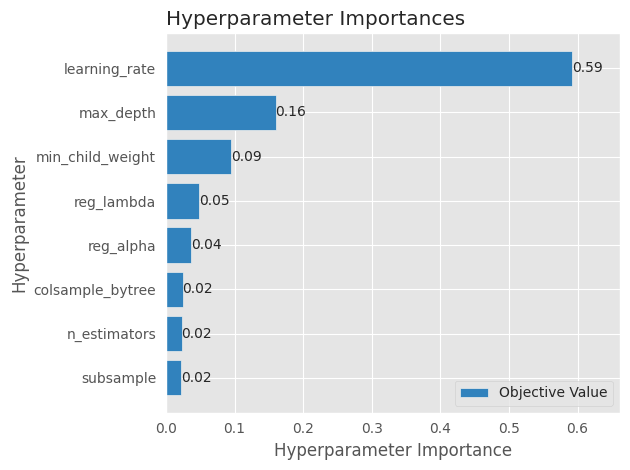

In [25]:
import optuna.visualization.matplotlib as optuna_mpl

optuna_mpl.plot_param_importances(study)
plt.tight_layout()
plt.show()


### Paso 2.5: Entrenar el modelo optimizado

Con `study.best_params`, entrena el modelo final de XGBoost sobre `X_train_fe`, y evaluá sobre `X_test_fe`. Compara el resultado contra el XGBoost por defecto del Paso 2.1: ¿el tuning realmente ayudo?


In [26]:
xgb_optimizado = XGBRegressor(**study.best_params, random_state=RANDOM_STATE)
xgb_optimizado.fit(X_train_fe, y_train_log)

y_pred_optimizado_log = xgb_optimizado.predict(X_test_fe)
y_pred_optimizado = np.expm1(y_pred_optimizado_log).clip(min=0)

rmse_optimizado = mean_squared_error(y_test, y_pred_optimizado) ** 0.5
r2_optimizado = r2_score(y_test, y_pred_optimizado)

print(f"RMSE optimizado: {rmse_optimizado:.2f} (default: {rmse_xgb_default:.2f})")
print(f"R2 optimizado: {r2_optimizado:.4f} (default: {r2_xgb_default:.4f})")


RMSE optimizado: 223.53 (default: 233.97)
R2 optimizado: 0.8727 (default: 0.8606)


## Comparativa Final

### Tabla comparativa

Arma una tabla con el **Modelo Inicial** (Regresion Lineal, sin feature engineering) y el **Modelo Optimizado** (XGBoost con las features de la Parte 1, mas el tuning de Optuna), mostrando el RMSE y el R2 de cada uno. Si quieres, agrega tambien las referencias intermedias (Regresion Lineal + FE, y XGBoost por defecto), para que la tabla cuente toda la historia.


In [27]:
comparativa = pd.DataFrame({
    "Modelo": [
        "Regresion Lineal (baseline, sin FE)",
        "Regresion Lineal + Feature Engineering",
        "XGBoost (parametros por defecto)",
        "XGBoost + Optuna (optimizado)",
    ],
    "RMSE": [rmse_inicial, rmse_fe, rmse_xgb_default, rmse_optimizado],
    "R2": [r2_inicial, r2_fe, r2_xgb_default, r2_optimizado],
})

comparativa


,Modelo,RMSE,R2
0,"Regresion Lineal (baseline, sin FE)",420.085041,0.550490
1,Regresion Lineal + Feature Engineering,378.375971,0.635320
2,XGBoost (parametros por defecto),233.972321,0.860558
3,XGBoost + Optuna (optimizado),223.527831,0.872729


### Conclusion

De las cuatro tecnicas de Feature Engineering aplicadas, la que mas impacto tuvo por si sola fue el log-transform del target, ya que corrigio el sesgo fuerte de rented_bike_count y le permitio a la Regresion Lineal capturar mejor los rangos bajos y altos de demanda al mismo tiempo. Sin embargo, el salto mas grande en todo el ejercicio no vino del Feature Engineering sino del cambio de modelo: pasar de Regresion Lineal a XGBoost redujo el RMSE de 378 a 234, casi un 40% de mejora, porque XGBoost puede capturar relaciones no lineales entre variables como temperatura, hora y estacion que un modelo lineal simplemente no ve.

El tuning con Optuna aporto una mejora adicional pero mas modesta (de 234 a 228 de RMSE), lo cual tiene sentido: los hiperparametros por defecto de XGBoost ya suelen ser razonablemente buenos, y la optimizacion bayesiana ayuda a exprimir ese ultimo margen, no a resolver problemas estructurales del modelo o los datos.

En conjunto, el orden de impacto fue: primero elegir un buen modelo (XGBoost sobre Regresion Lineal), despues el Feature Engineering (especialmente el log-transform y el Target Encoding de hour), y por ultimo el tuning fino de hiperparametros.
